In [1]:
import matplotlib.pyplot as plt
import os
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
from collections import Counter
from math import ceil
from PIL import Image
from sklearn.metrics import confusion_matrix
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder

sns.set_theme()

(current_device := torch.device("cuda" if torch.cuda.is_available() else "cpu"))

device(type='cuda')

# Подготовка тестовых данных

In [2]:
# Среднее и стандартное отклонение по трём цветовым каналам, посчитанные на ImageNet
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]
image_size = 224
batch_size = 32

transform_base = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])

photos_path = "./test/photos"
photos_dataset = ImageFolder(photos_path, transform=transform_base)

photos_targets = photos_dataset.targets
n_photos = len(photos_dataset)

photos_loader = DataLoader(photos_dataset, batch_size=batch_size, shuffle=False)

class_names = photos_dataset.classes
n_classes = len(class_names)

photos_counts = {class_names[target]: cnt for target, cnt in Counter(photos_dataset.targets).items()}

print("Новые изображения каждого класса:")
for class_name, cnt in photos_counts.items():
    print(f"'{class_name}': {cnt}")

Новые изображения каждого класса:
'dew': 12
'fogsmog': 12
'frost': 12
'glaze': 12
'hail': 12
'lightning': 12
'rain': 12
'rainbow': 12
'rime': 12
'sandstorm': 12
'snow': 12


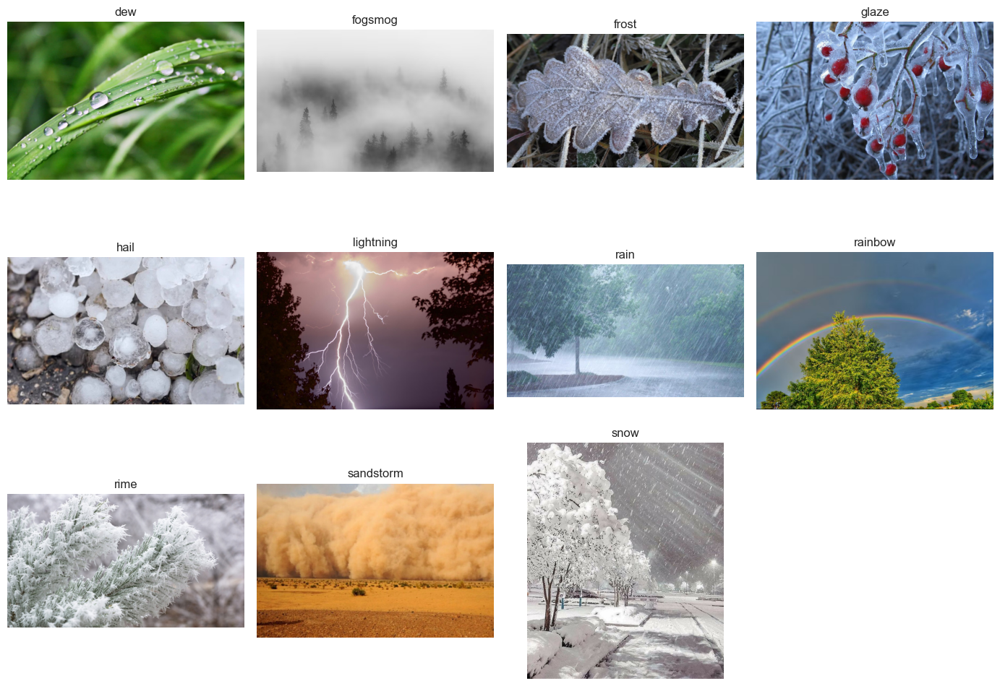

In [3]:
fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(14, 10))
axes = axes.flatten()

for i, class_name in enumerate(class_names):
    class_dir = os.path.join(photos_path, class_name)
    image_path = os.path.join(class_dir, os.listdir(class_dir)[0])
    
    axes[i].imshow(Image.open(image_path))
    axes[i].axis("off")
    axes[i].set_title(class_name)

axes[-1].axis("off")

plt.tight_layout()

# Инициализация моделей

In [4]:
class WeatherMLP(nn.Module):
    def __init__(self, n_classes):
        super().__init__()

        # (batch, 3, 224, 224) -> (batch, 3, 16, 16)
        self.input_pool = nn.AdaptiveAvgPool2d((16, 16))

        self.classifier = nn.Sequential(
            nn.Flatten(),  # (batch, 3, 16, 16) -> (batch, 768)
            nn.Linear(3 * 16 * 16, 512),  # (batch, 768) -> (batch, 512)
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, 256),  # (batch, 512) -> (batch, 256)
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, n_classes)  # (batch, 256) -> (batch, n_classes)
        )

    def forward(self, x):
        x = self.input_pool(x)
        return self.classifier(x)


class WeatherCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()

        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),  # (batch, 3, 224, 224) -> (batch, 32, 224, 224)
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),  # (batch, 32, 224, 224) -> (batch, 32, 224, 224)
            nn.ReLU(),
            nn.MaxPool2d(2),  # (batch, 32, 224, 224) -> (batch, 32, 112, 112)
            nn.Dropout2d(0.2),
        )

        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),  # (batch, 32, 112, 112) -> (batch, 64, 112, 112)
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),  # (batch, 64, 112, 112) -> (batch, 64, 112, 112)
            nn.ReLU(),
            nn.MaxPool2d(2),  # (batch, 64, 112, 112) -> (batch, 64, 56, 56)
            nn.Dropout2d(0.3),
        )

        self.conv_block_3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),  # (batch, 64, 56, 56) -> (batch, 128, 56, 56)
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),  # (batch, 128, 56, 56) -> (batch, 128, 56, 56)
            nn.ReLU(),
            nn.MaxPool2d(2),  # (batch, 128, 56, 56) -> (batch, 128, 28, 28)
            nn.Dropout2d(0.4),
        )

        self.conv_block_4 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1),  # (batch, 128, 28, 28) -> (batch, 256, 28, 28)
            nn.ReLU(),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),  # (batch, 256, 28, 28) -> (batch, 256, 28, 28)
            nn.ReLU(),
            nn.MaxPool2d(2),  # (batch, 256, 28, 28) -> (batch, 256, 14, 14)
            nn.Dropout2d(0.4),
        )

        # (batch, 256, 14, 14) -> (batch, 256, 4, 4)
        self.global_pool = nn.AdaptiveAvgPool2d((4, 4))

        self.classifier = nn.Sequential(
            nn.Flatten(),  # (batch, 256, 4, 4) -> (batch, 4096)
            nn.Linear(256 * 4 * 4, 256),  # (batch, 4096) -> (batch, 256)
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, n_classes),  # (batch, 256) -> (batch, n_classes)
        )

    def forward(self, x):
        x = self.conv_block_1(x)
        x = self.conv_block_2(x)
        x = self.conv_block_3(x)
        x = self.conv_block_4(x)
        x = self.global_pool(x)
        return self.classifier(x)


resnet18 = models.resnet18()
resnet18.fc = nn.Linear(resnet18.fc.in_features, n_classes)

mobilenet_v3_large = models.mobilenet_v3_large()
mobilenet_v3_large.classifier[3] = nn.Linear(mobilenet_v3_large.classifier[3].in_features, n_classes)

efficientnet_b0 = models.efficientnet_b0()
efficientnet_b0.classifier[1] = nn.Linear(efficientnet_b0.classifier[1].in_features, n_classes)

models_dict = {
    "WeatherMLP": WeatherMLP(n_classes=n_classes),
    "WeatherCNN": WeatherCNN(n_classes=n_classes),
    "ResNet18": resnet18,
    "MobileNetV3-Large": mobilenet_v3_large,
    "EfficientNet-B0": efficientnet_b0,
}

models_short = {
    "WeatherMLP": "MLP",
    "WeatherCNN": "CNN",
    "ResNet18": "ResNet",
    "MobileNetV3-Large": "MobNet",
    "EfficientNet-B0": "EffNet",
}

for model_name, model in models_dict.items():
    model = model.to(current_device)
    model.load_state_dict(
        torch.load(f"./models/{model_name}.pt", map_location=current_device)
    )
    params = sum(p.numel() for p in model.parameters())
    print(f"{model_name}: {params} параметров")

WeatherMLP: 527883 параметров
WeatherCNN: 2223915 параметров
ResNet18: 11182155 параметров
MobileNetV3-Large: 4216123 параметров
EfficientNet-B0: 4021639 параметров


# Тестирование моделей на новых фотографиях

In [5]:
def evaluate_predict(model, loader, device):
    model.eval()

    correct, total = 0, 0
    all_preds, all_probs = [], []

    with torch.no_grad():
        for inputs, targets in loader:
            inputs, targets = inputs.to(device), targets.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            probs = torch.softmax(outputs, dim=1)

            correct += (preds == targets).sum().item()
            total += targets.size(0)

            all_preds.append(preds.cpu())
            all_probs.append(probs.cpu())
    
    return correct / total, torch.cat(all_preds).numpy(), torch.cat(all_probs).numpy()


def get_image_array_from_tensor(image_tensor):
    mean_tensor = torch.tensor(mean).view(3, 1, 1)
    std_tensor = torch.tensor(std).view(3, 1, 1)

    image_tensor = image_tensor * std_tensor + mean_tensor
    image_tensor = image_tensor.clamp(0, 1)
    image_array = image_tensor.permute(1, 2, 0).detach().cpu().numpy()

    return image_array


def plot_preds(class_name, dataset, path, all_preds):
    n_models = len(all_preds)

    class_label = dataset.class_to_idx[class_name]
    image_indices = [i for i, label in enumerate(dataset.targets) if label == class_label]

    class_dir = os.path.join(path, class_name)
    image_paths = []
    n_images = 0

    for image_name in os.listdir(class_dir):
        image_paths.append(os.path.join(class_dir, image_name))
        n_images += 1

    n_cols = 4
    n_rows = ceil(n_images / n_cols)

    _, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(14, n_rows * 4.5))
    axes = axes.flatten()

    for i, image_index in enumerate(image_indices):
        ax = axes[i]

        ax.imshow(get_image_array_from_tensor(dataset[image_index][0]))
        ax.axis("off")

        model_names = [models_short[preds["model"]] for preds in all_preds]
        image_preds = [preds["preds"][image_index] for preds in all_preds]
        image_probs = [preds["probs"][image_index][image_preds[j]] for j, preds in enumerate(all_preds)]

        y_step = 0.075
        y_start = 1.02 + y_step * (n_models - 1)
        for k, model_name, pred, prob in zip(range(n_models), model_names, image_preds, image_probs):
            color = "green" if class_names[pred] == class_name else "red"
            line = f"{model_name}: {class_names[pred]} ({prob:.2f})"
            ax.text(
                0.5, y_start - k * y_step, line, transform=ax.transAxes,
                ha="center", va="bottom", color=color
            )

    for i in range(n_images, len(axes)):
        axes[i].axis("off")

    plt.subplots_adjust(wspace=0.1, hspace=0.2)

In [6]:
photos_preds = []
for model_name, model in models_dict.items():
    acc, preds, probs = evaluate_predict(model, photos_loader, current_device)
    cm = confusion_matrix(photos_targets, preds)
    photos_preds.append({
        "model": model_name,
        "acc": acc,
        "preds": preds,
        "probs": probs,
        "cm": cm,
    })

photos_results = []
for preds in photos_preds:
    correct = (preds["preds"] == photos_targets).sum().item()
    photos_results.append({
        "Модель": preds["model"],
        "Точность": f"{preds["acc"]:.4f}",
        "Ошибок": n_photos - correct,
    })

pd.DataFrame(photos_results).style.hide(axis="index")

Модель,Точность,Ошибок
WeatherMLP,0.5227,63
WeatherCNN,0.6970,40
ResNet18,0.8712,17
MobileNetV3-Large,0.8636,18
EfficientNet-B0,0.9015,13


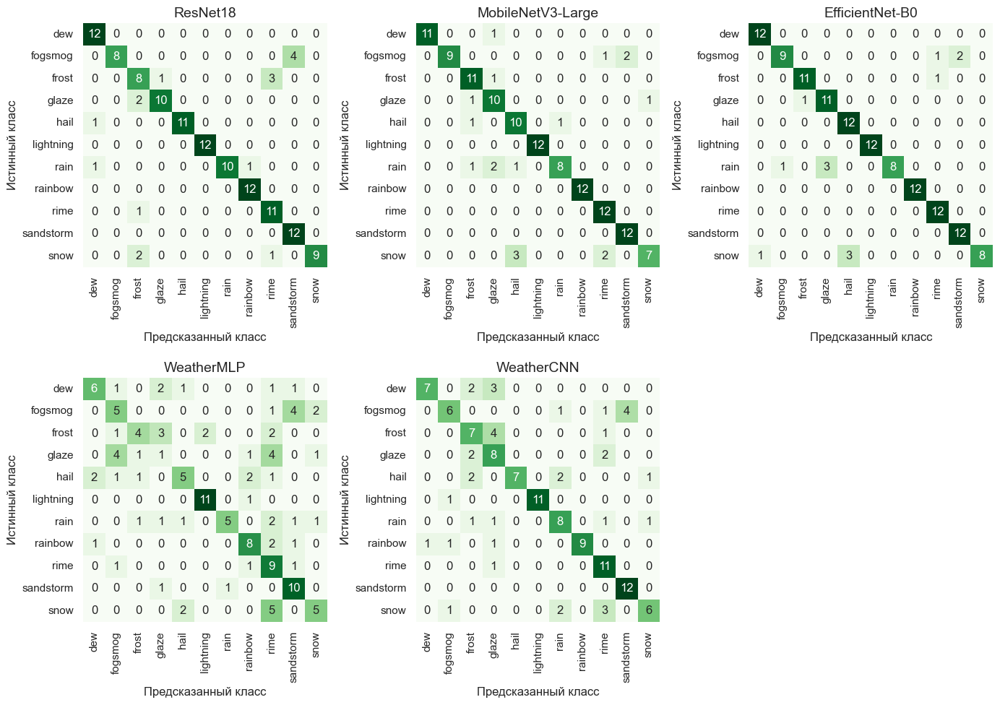

In [7]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(14, 10))
axes = axes.flatten()

for i, preds in enumerate(photos_preds[2:] + photos_preds[:2]):
    sns.heatmap(
        preds["cm"], cmap="Greens", annot=True, fmt="d", cbar=False, square=True, ax=axes[i]
    ).set(
        xlabel="Предсказанный класс", ylabel="Истинный класс",
        xticklabels=class_names, yticklabels=class_names
    )
    axes[i].set_title(preds["model"], fontsize=14)
    axes[i].tick_params(axis="x", rotation=90)
    axes[i].tick_params(axis="y", rotation=0)

axes[-1].axis("off")

plt.tight_layout()

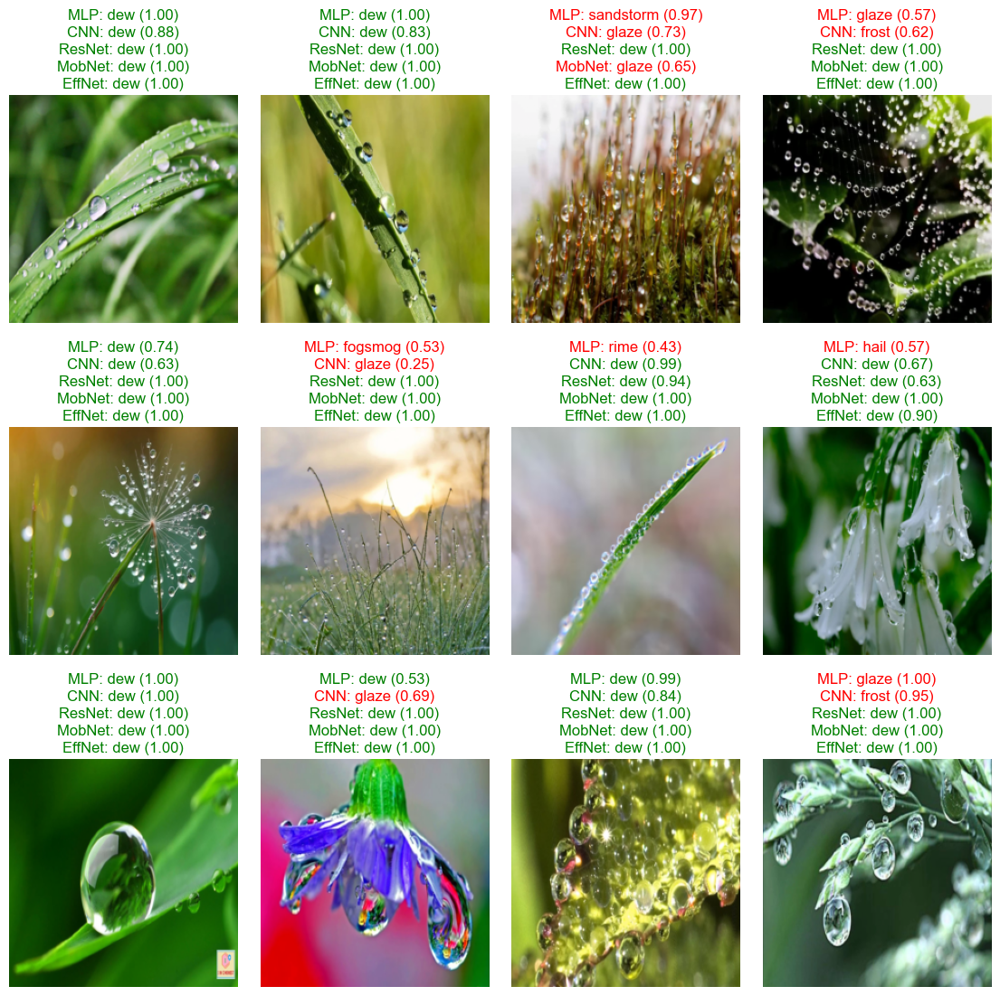

In [8]:
plot_preds("dew", dataset=photos_dataset, path=photos_path, all_preds=photos_preds)

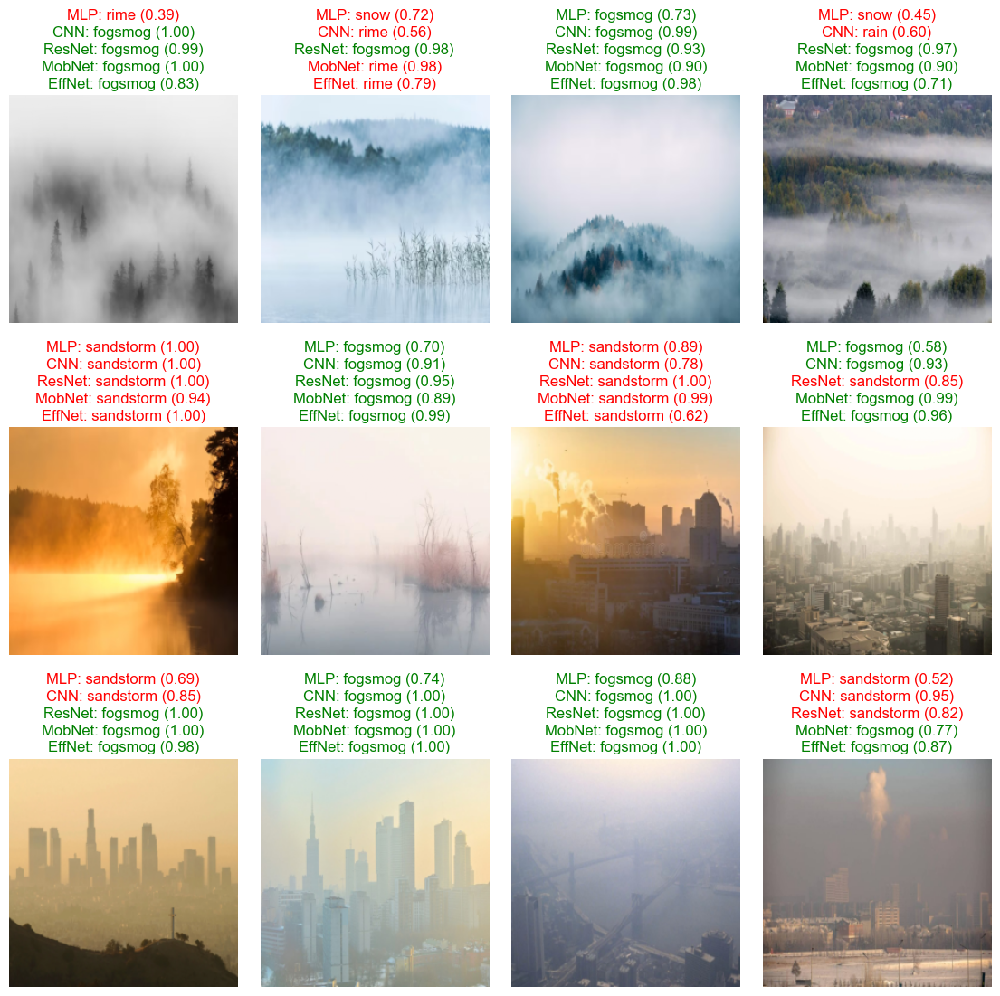

In [9]:
plot_preds("fogsmog", dataset=photos_dataset, path=photos_path, all_preds=photos_preds)

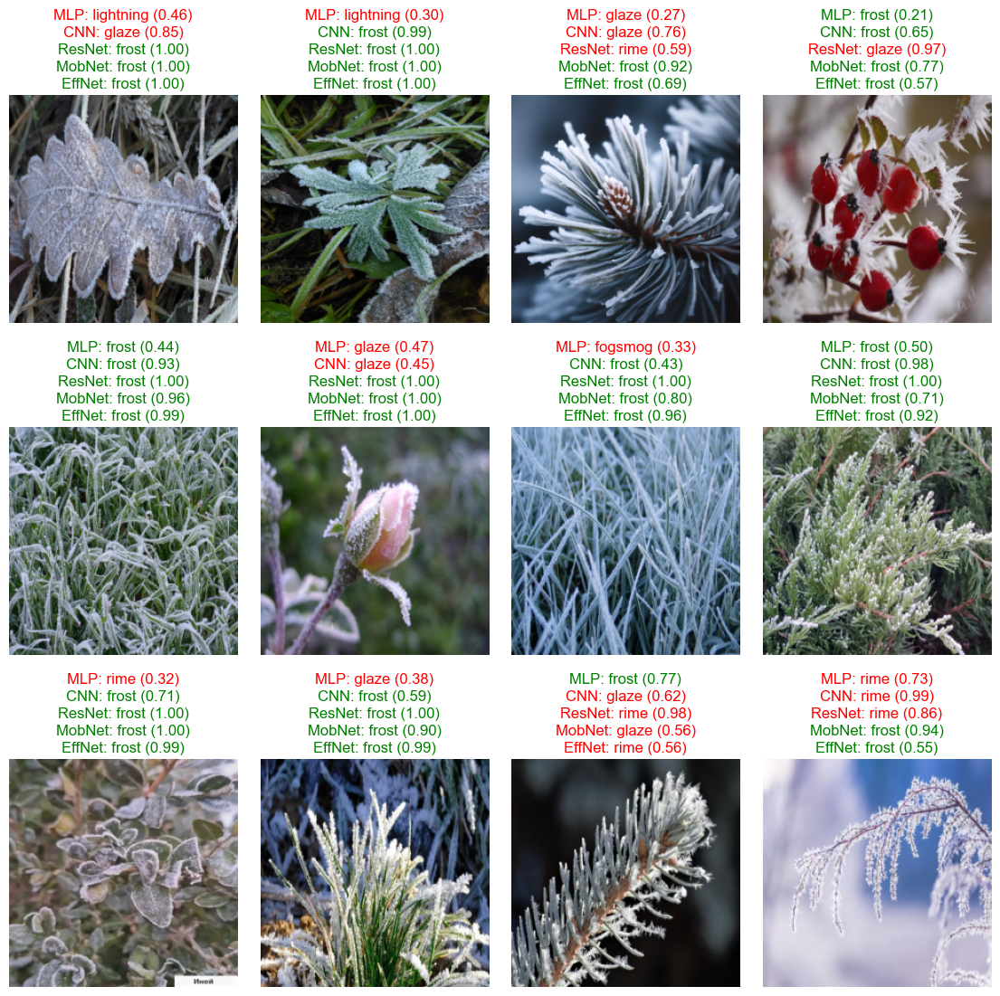

In [10]:
plot_preds("frost", dataset=photos_dataset, path=photos_path, all_preds=photos_preds)

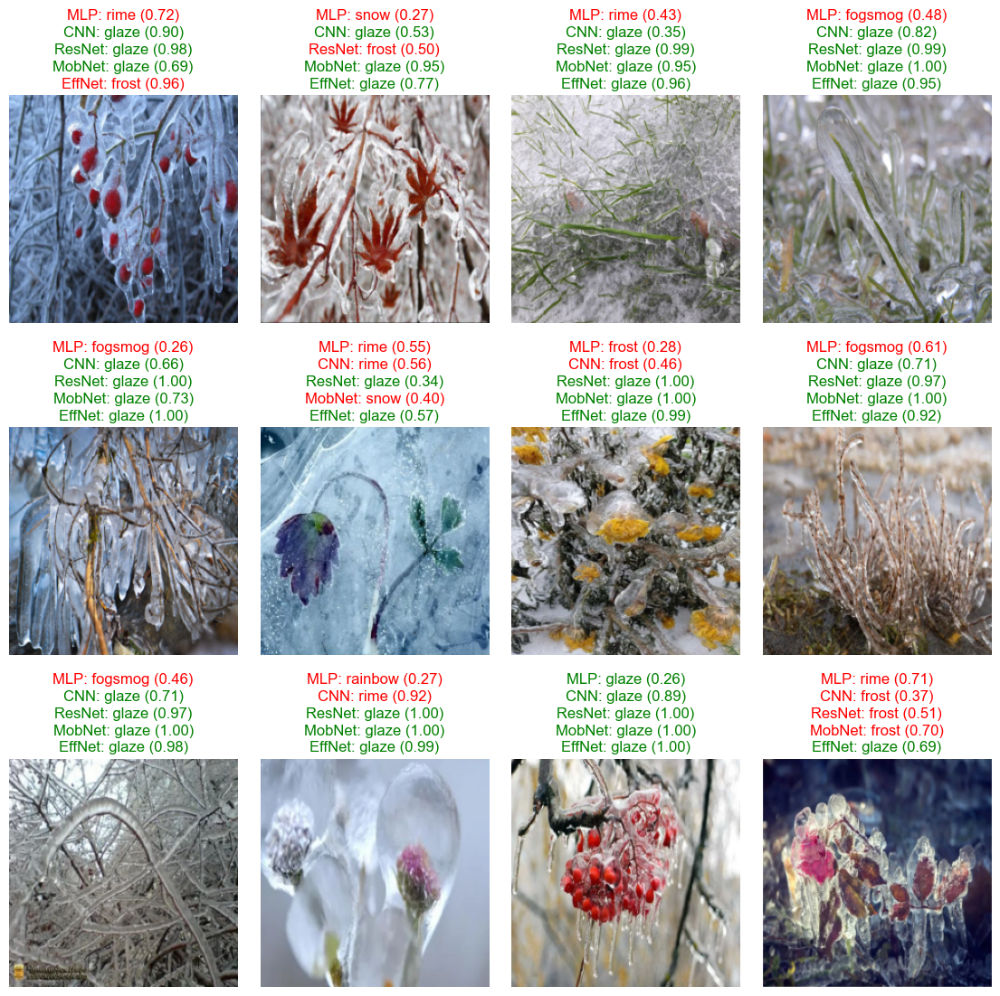

In [11]:
plot_preds("glaze", dataset=photos_dataset, path=photos_path, all_preds=photos_preds)

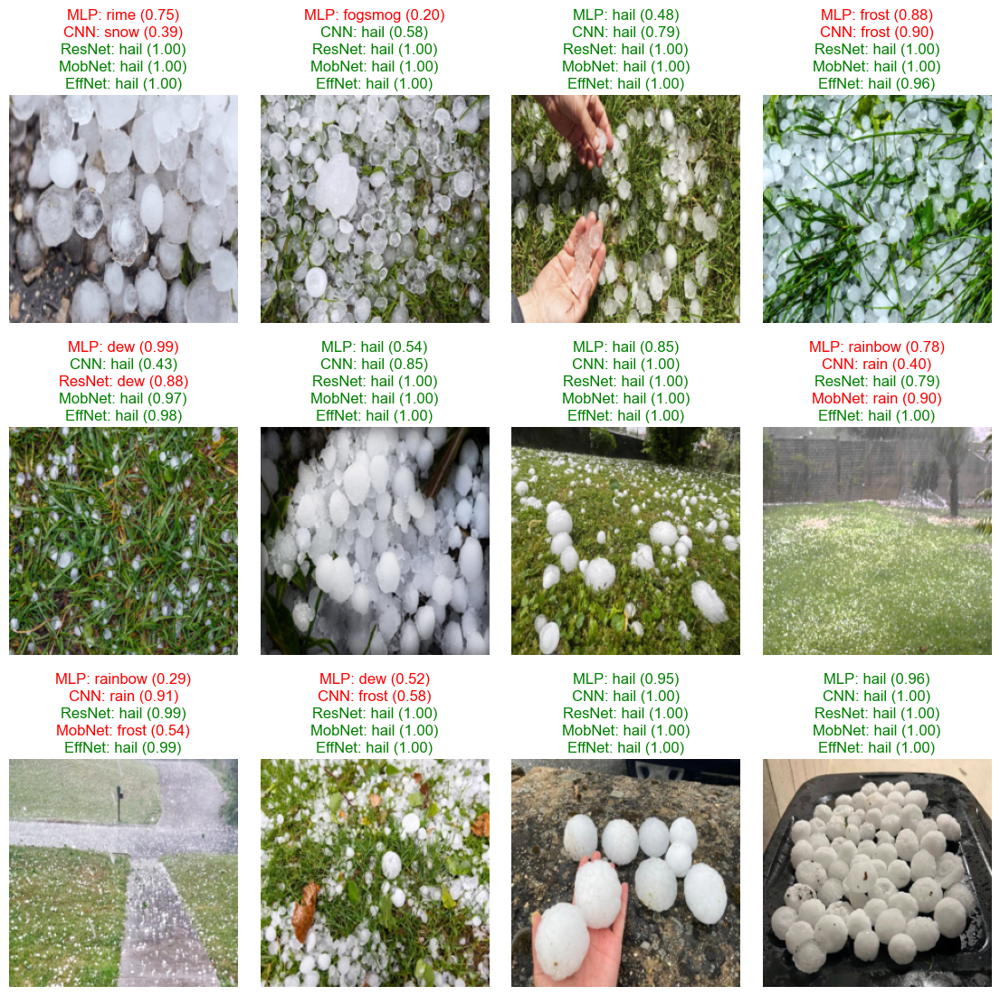

In [12]:
plot_preds("hail", dataset=photos_dataset, path=photos_path, all_preds=photos_preds)

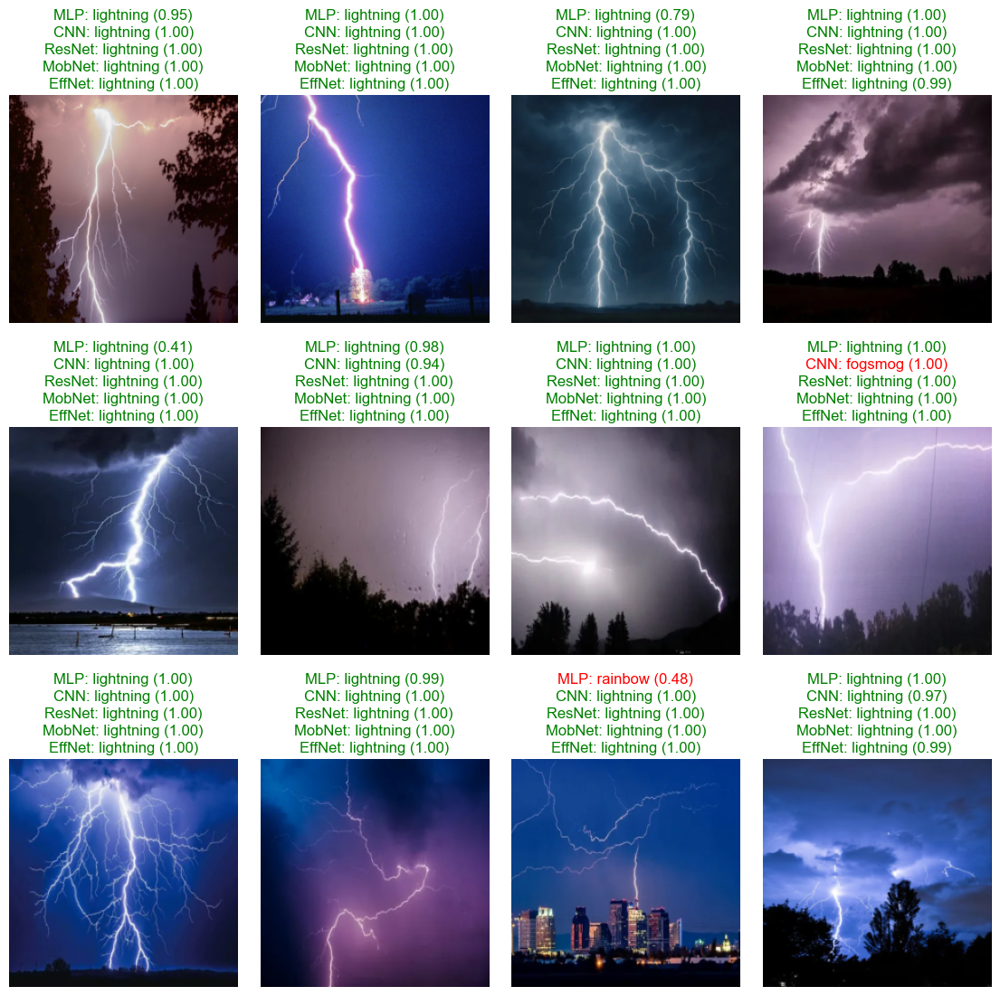

In [13]:
plot_preds("lightning", dataset=photos_dataset, path=photos_path, all_preds=photos_preds)

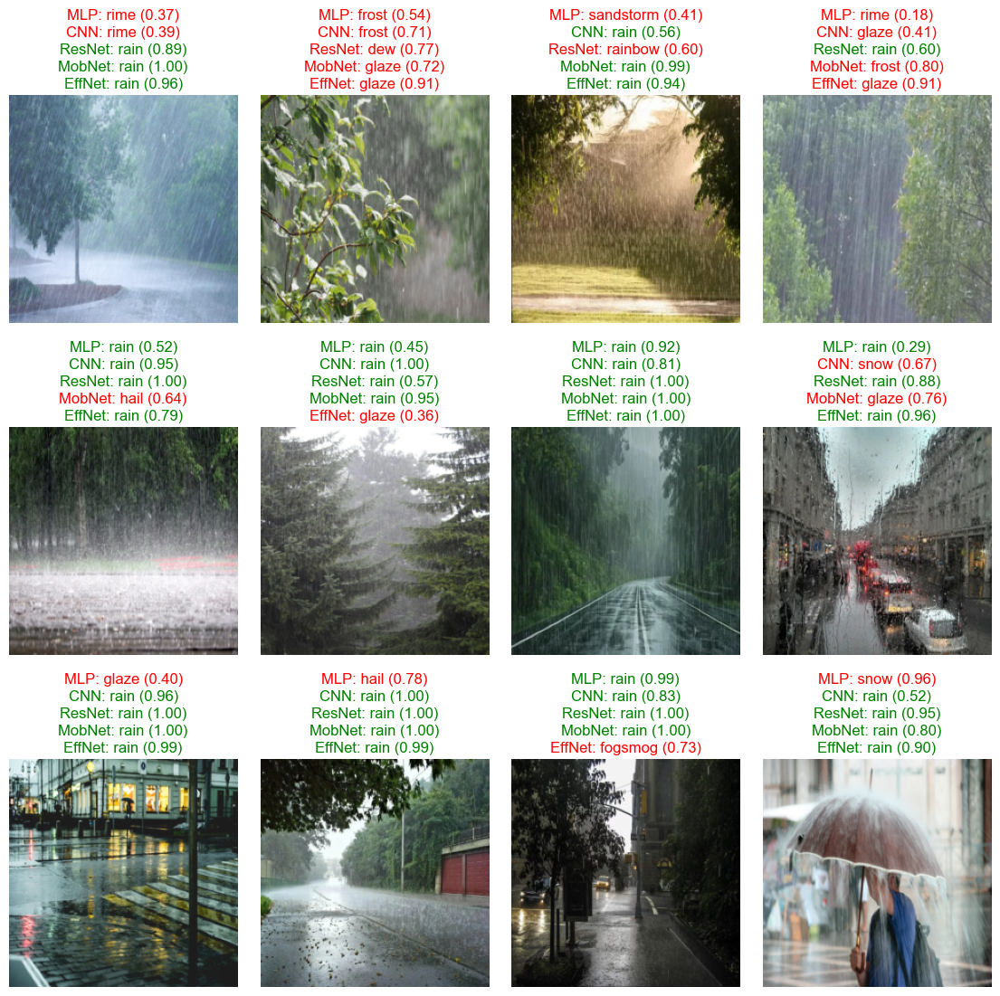

In [14]:
plot_preds("rain", dataset=photos_dataset, path=photos_path, all_preds=photos_preds)

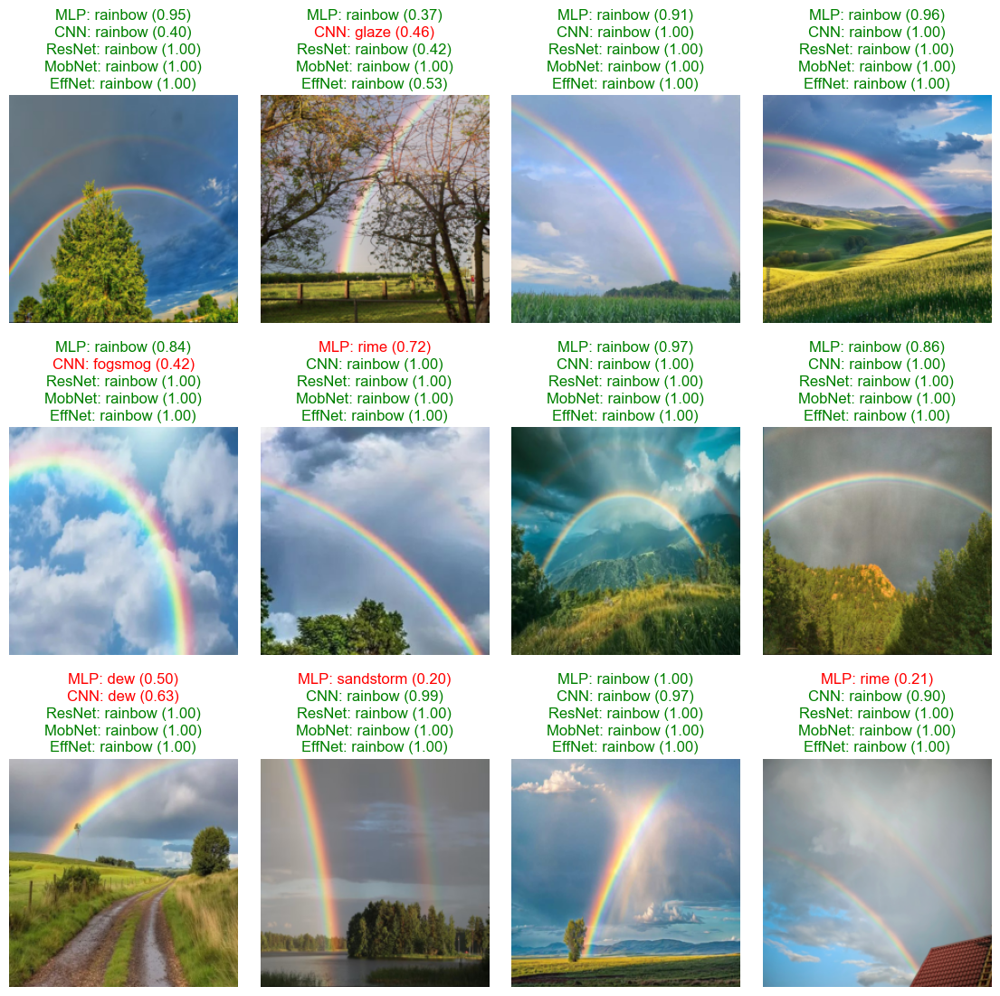

In [15]:
plot_preds("rainbow", dataset=photos_dataset, path=photos_path, all_preds=photos_preds)

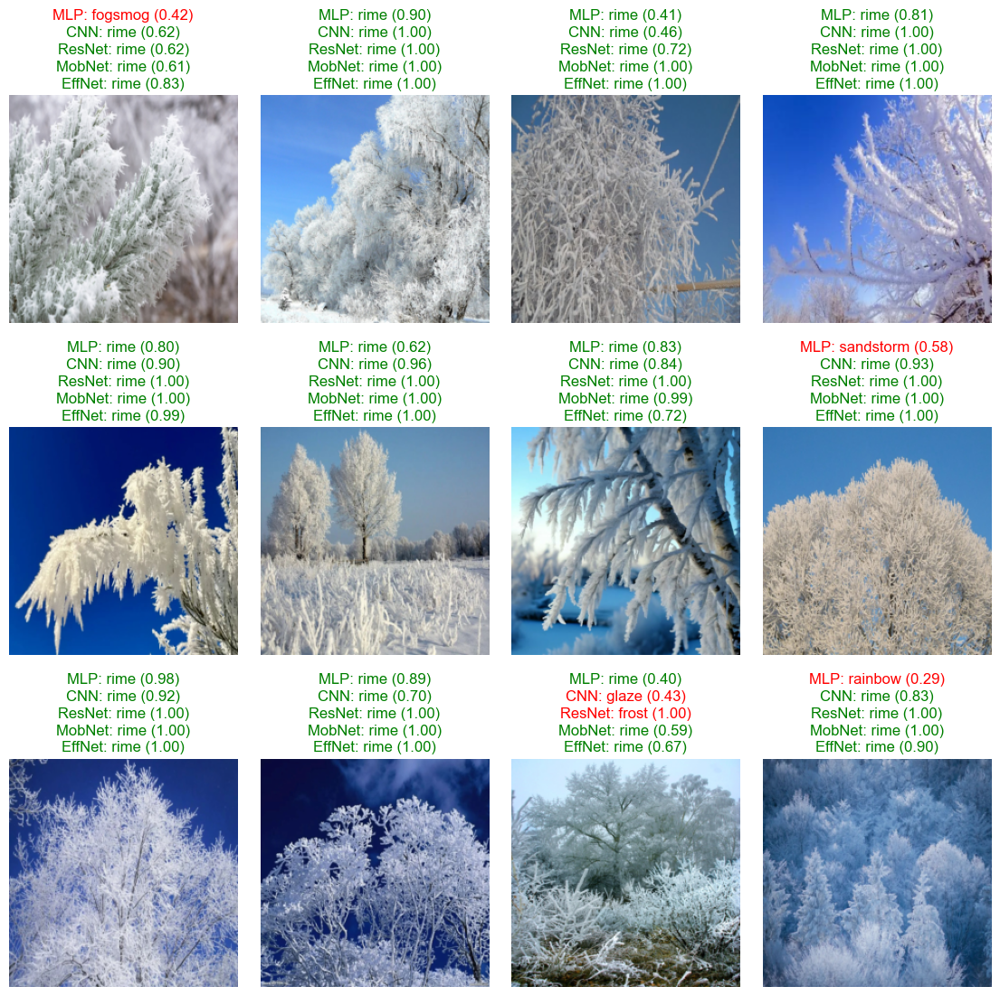

In [16]:
plot_preds("rime", dataset=photos_dataset, path=photos_path, all_preds=photos_preds)

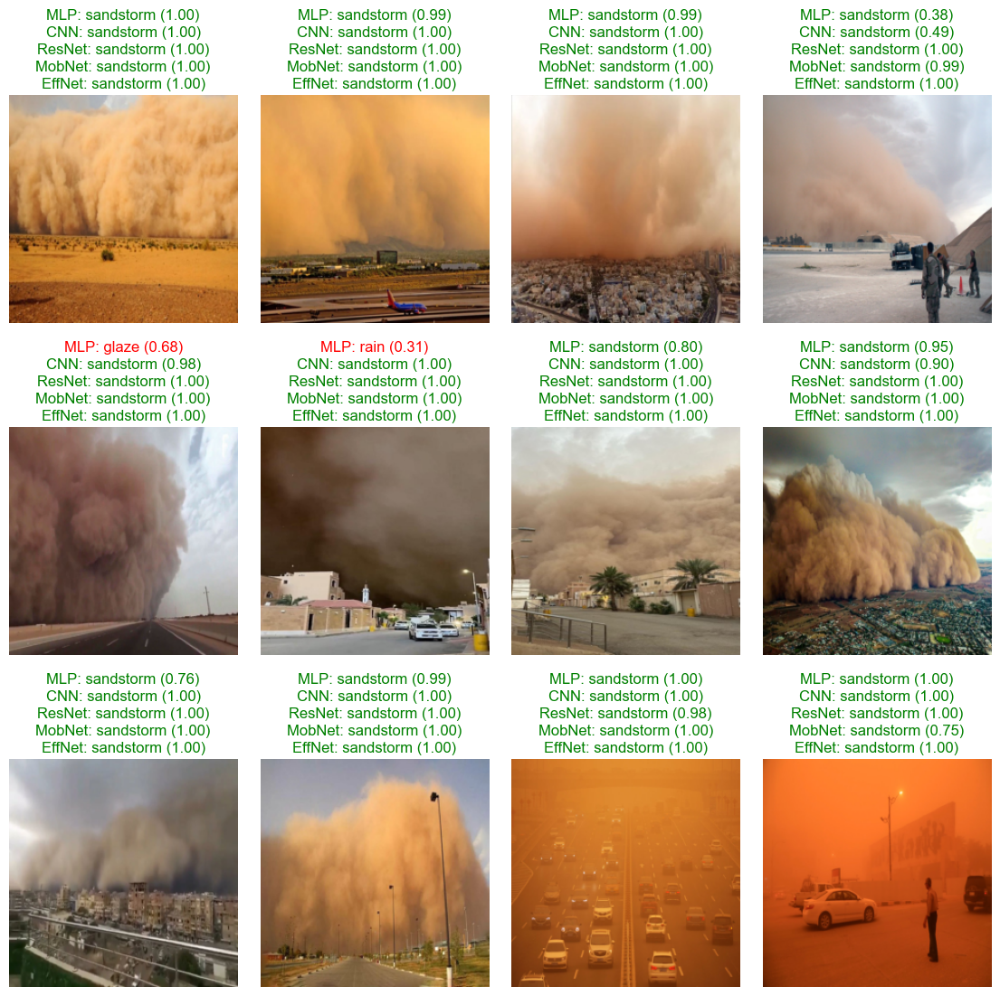

In [17]:
plot_preds("sandstorm", dataset=photos_dataset, path=photos_path, all_preds=photos_preds)

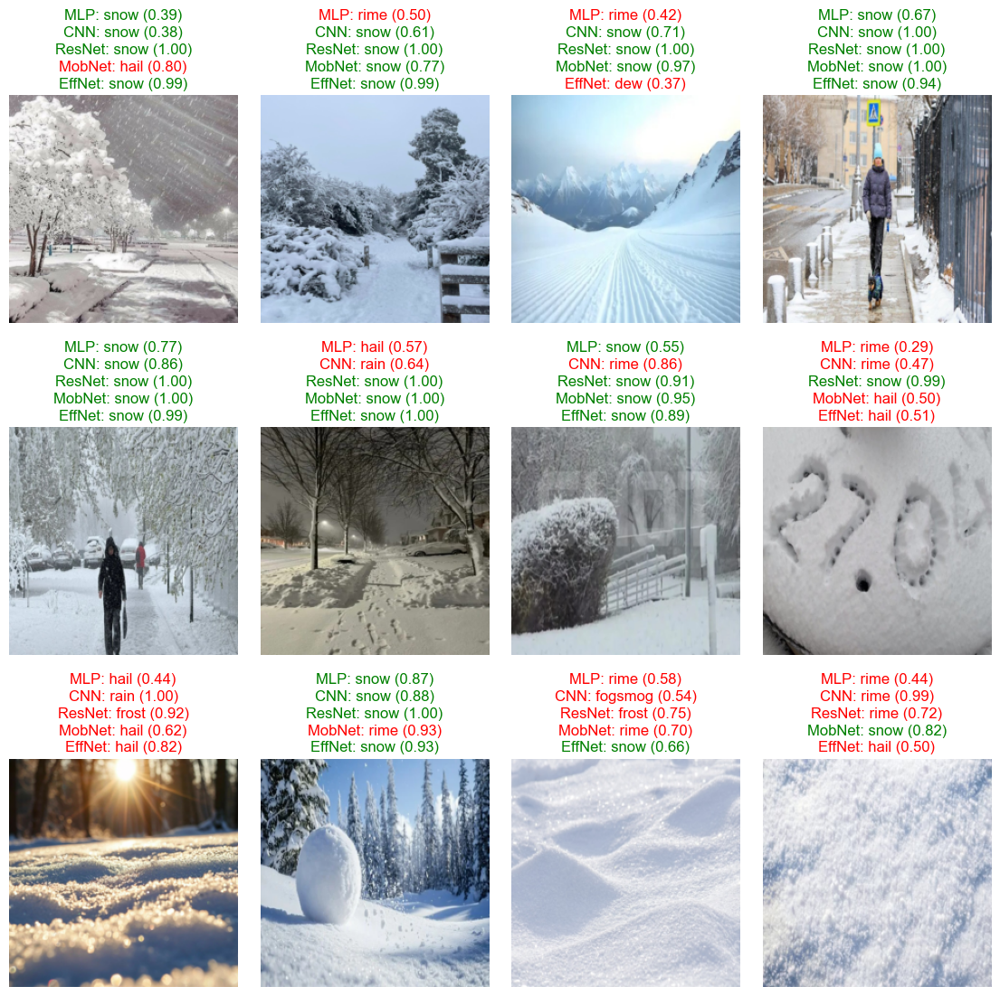

In [18]:
plot_preds("snow", dataset=photos_dataset, path=photos_path, all_preds=photos_preds)